# Лабораторная работа №1
## Системы искусственного интеллекта и машинное обучение

**Тема:** Линейная регрессия и факторный анализ

**Студентка:** Лантух Елизавета Евгеньевна
**Группа:** АВТ-313

## 1. Введение
**Цель работы:** изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качество.

**Постановка задачи:**

Провести обучение модели линейной регрессии на датасете с Kaggle:

1. Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).

2. Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной. 

3. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).

4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).

5. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).

6. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.
Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.

## 2. Описание датасета

В датасете представлены данные по продажам в кофейне. Есть следующие столбцы:

1. transaction_id: уникальный номер банковской транзакции
2. transaction_date: дата банковской транзакции
3. transaction_time: время банковской транзакции
4. transaction_qty: количество единиц в чеке
5. store_id: уникальный номер магазина
6. store_location: название района, где находится магазин
7. product_id: уникальный идентификатор товара
8. unit_price: цена за единицу товара
9. product_category: категория продукта (напитки, выпечка и т.д.)
10. product_type: тип продукта (классификация внутри категории)
11. product_detail: сорт, размер, особенности товара
12. revenue: сумма в чеке (в долларах)

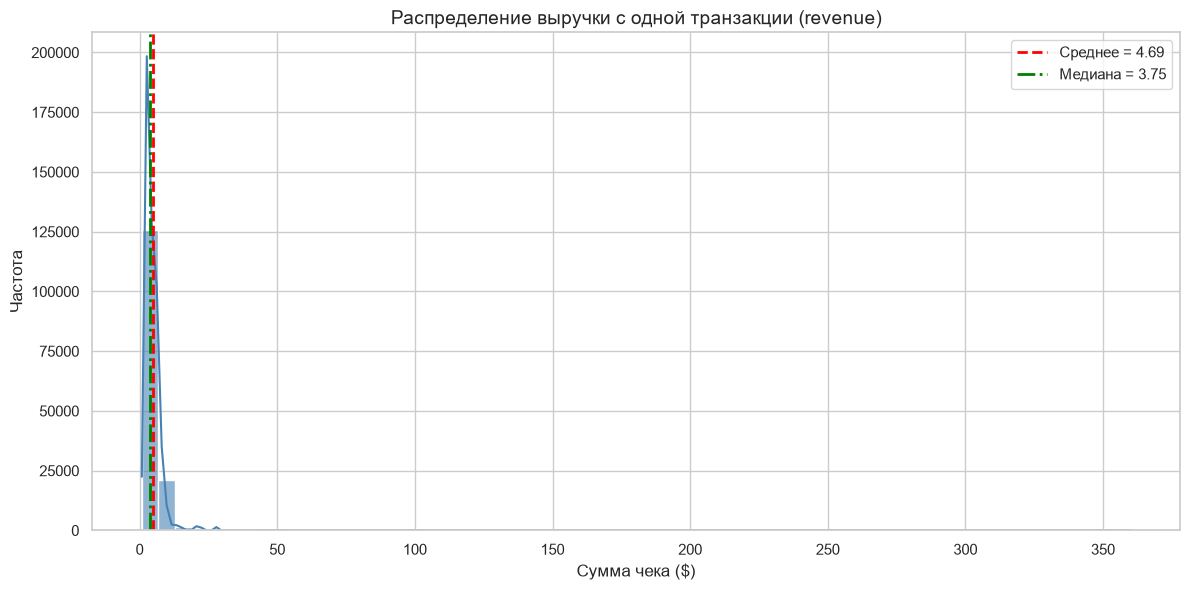
Распределение суммы чека экспоненциальное

## 3. Подготовка данных

Проверка пропущенных данных была выполнена с помощью функции df.isnull().sum(). По результатам проверки пропуски не были обнаружены.

Распределение данных по категориям было выполнено с помощью функции df.info(). По резульатам проверки было выявлено 6 числовых и 6 категориальных признаков.

Столбцы со временем и датой были переведены в соответствующие типы:

Категориальные переменные были закодированы методом One-Hot Encoding

In [ ]:
df_encoded = pd.get_dummies(
    df,
    columns=['product_category', 'store_location'],
    drop_first=True,
    dtype=int
)

Для оценки качества моделей данные разделены на две части в пропорциях 80/20 (80% данных для обучения, 20% данных для тестирования):

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Для нормализации данные были приведены к нулевому среднему значению и единичной дисперсии

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Ход работы

После приведения типов данных были построены таблица корреляции и VIF-графики

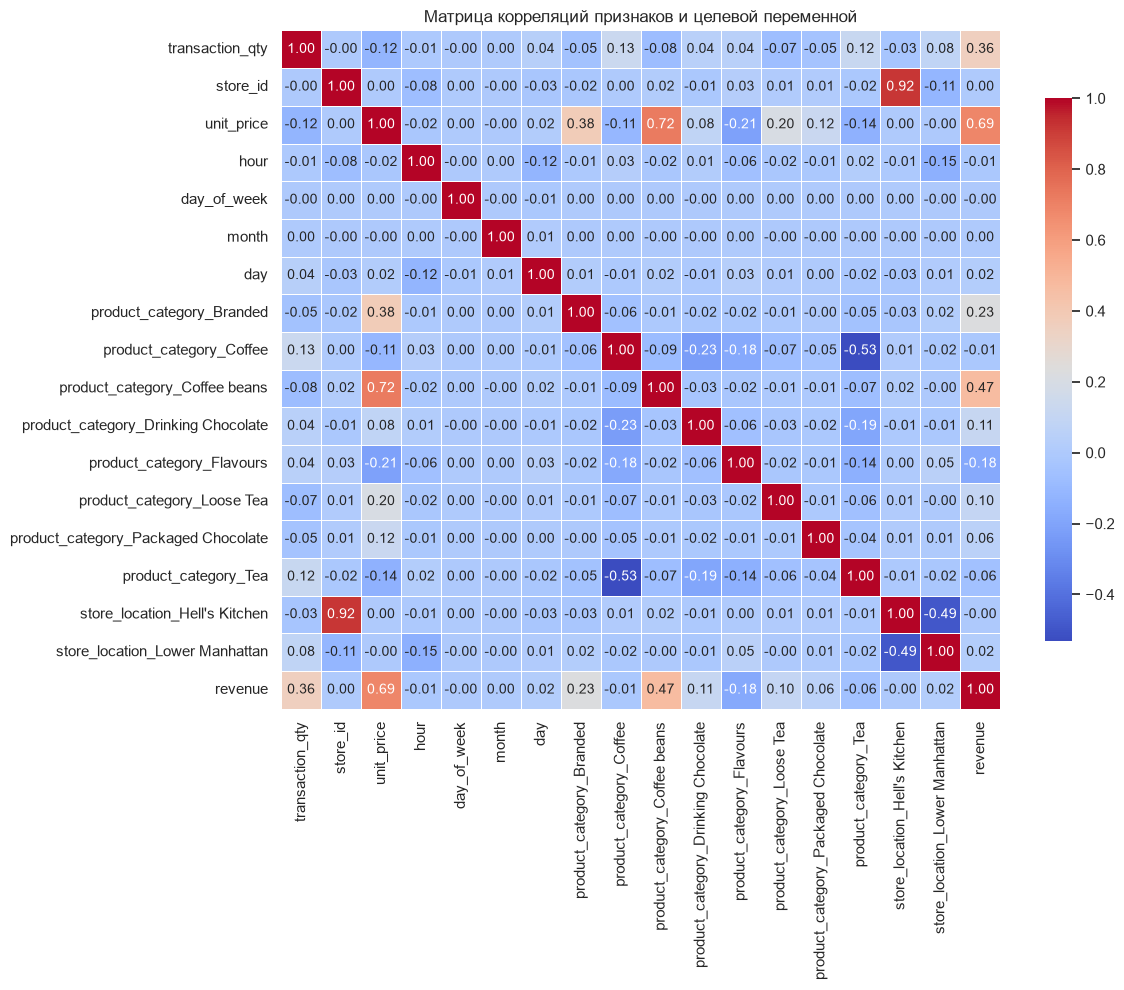
Таблица корреляций

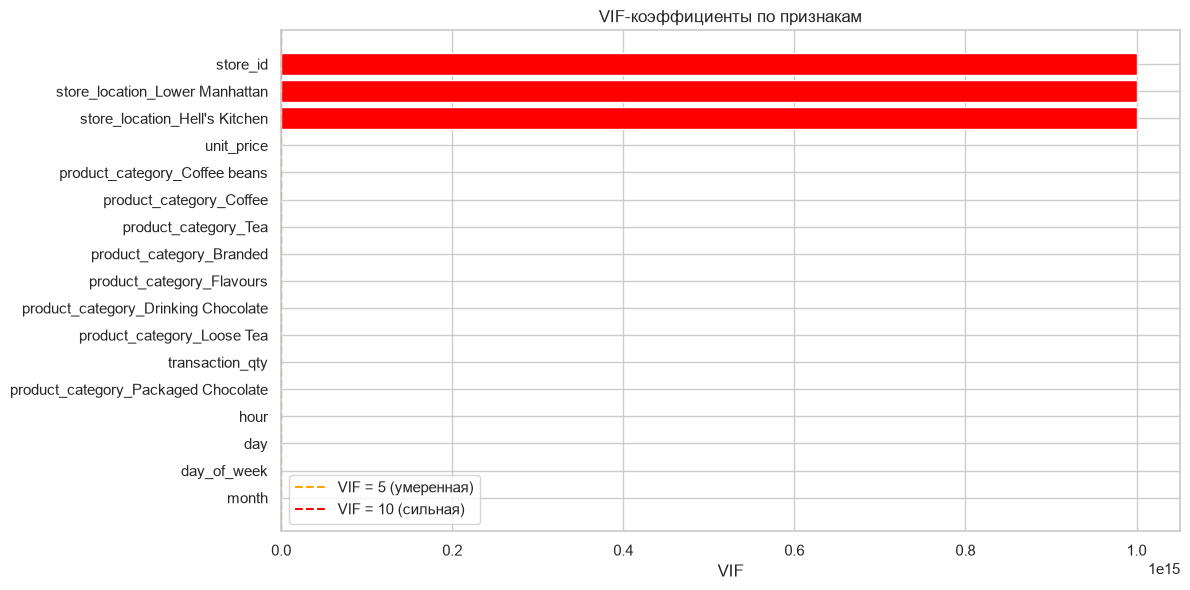
Расчет VIF-коэффициентов

Были выбраны 3 регрессивные модели:

- Линейная регрессия: позволяет оценить идеальное качество без штрафов
- Лассо регрессия (L1-регуляризация): используется тогда, когда часть признаков неинформативна. L1-штраф зануляет слабые коэффициенты
- Гребневая регрессия (L2-регуляризация): работает для мультиколлинеарности

Параметры:
Lasso (для лассо регрессии): α = 0.01 (штраф)
Ridge (для гребневой регрессии): α = 1.0 (стандартное значение по умолчанию)

Используемые метрики качества:
- RMSE: средняя ошибка
- R²: доля объясненное дисперсии
- MAPE: ошибка в процентах

Устранение мультиколлинеарности с помощью РСА:

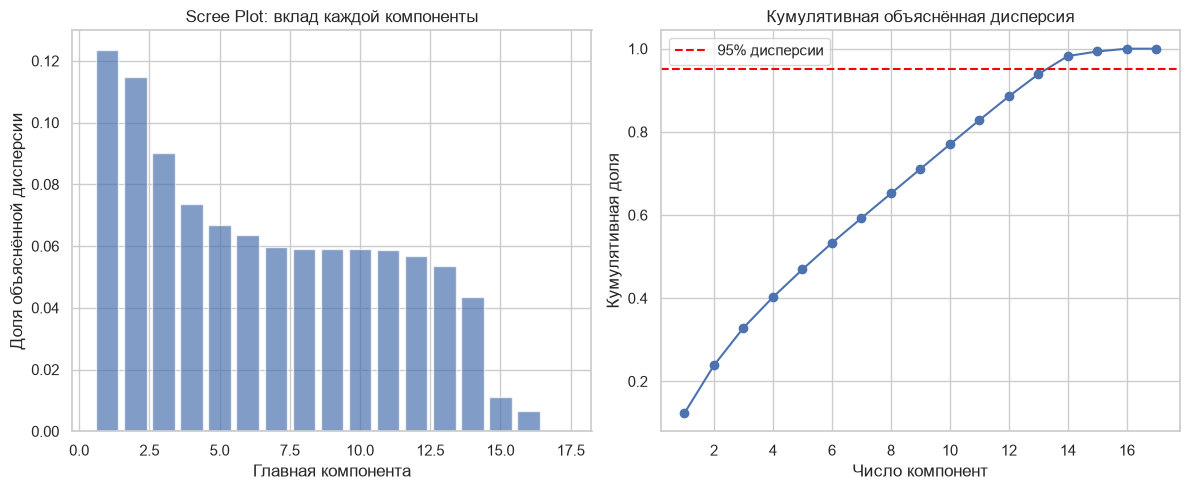

Основные метрики до и после устранения мультиколлинеарности:

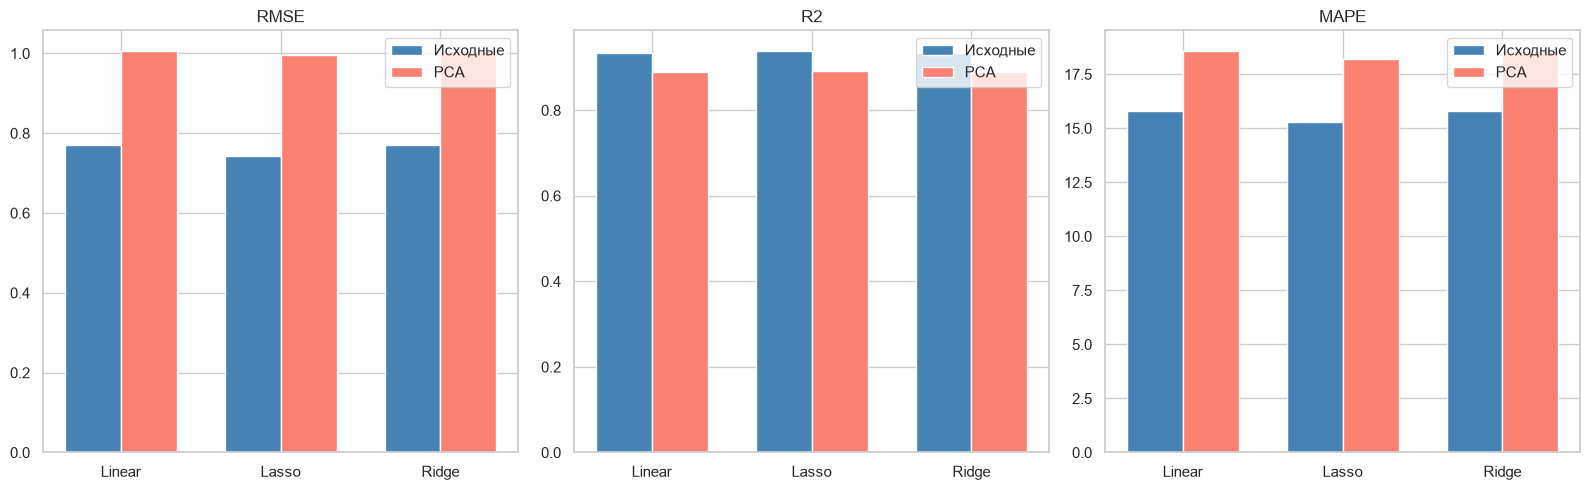


## 5. Заключение

По таблице корреляций можно сделать такие выводы:

- Кофейные зерна стоят дороже других товаров
- При покупке кофейных зерен цена чека увеличивается
- Брендовые товары стоят дороже обычных
- Чем дороже единица товара, тем больше сумма чека
- Когда покупают чай, редко покупают кофе (и наоборот)

По графикам VIF-коэффициентов можно сделать такие выводы:

Признаки sore_id, store_location_Lower_Manhattan, store_location_Hell's_Kitchen, сильно связан с другими, следовательно, мешает модели, поэтому его необходимо удалить.

РСА (каменистая осыпь):

Согласно графику распределения компонент, минимальное количество компонент, которые необходимо оставить, это 13. Первая компонента объясняет 12% дисперсии, вторая 11%, следующие меньше.

Сравнение Исходных данных и данных РСА:

RMSE: чем столбцы ниже, тем метрики лучше
Модели на PCA-компонентах дают более худшее качество метрик, чем модели с исходными признаками.

R2: чем ближе к 1, тем метрики лучше
Модели на PCA-компонентах дают сопоставимое качество метрик с моделями с исходными признаками.

MAPE: чем столбцы ниже, тем анализ лучше
Модели на PCA-компонентах дают незначительно худшее качество метрик по сравнению с моделями с исходными признаками.


Модель "предсказано - реально"

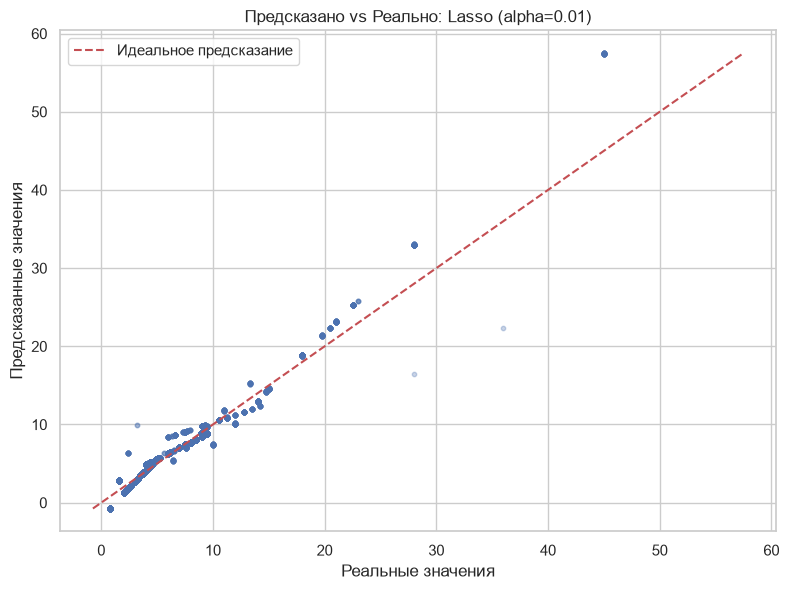

Можно увидеть, что точки плотно лежат вдоль красной линии, что говорит о том что наша модель хорошо предсказывает типичные значения выручки, однако допускает отдельные ошибки на крупных чеках.

## 6. Список источников

1. Маркелов Г. Е. Линейные регрессионные модели : учебно-методическое пособие. — 2-е изд., испр. — Москва : Изд-во МГТУ им. Н. Э. Баумана, 2024. — 48 с. — ISBN 978-5-7038-6382-4.
2. Елисейкин С. А., Климов А. С., Подрезов В. А. Метод главных компонент в инженерных задачах : учебно-справочное издание. — Королёв, Обнинск : ВНИИГМИ-МЦД, 2024. — 47 с. — ISBN 978-5-6050994-6-8. 
3. Кремер Н. Ш., Путко Б. А. Регрессионный анализ : учебник и практикум для вузов. — 4-е изд. — Москва : Юрайт, 2025.
4. Берикашвили В. Ш., Оськин С. П. Статистическая обработка данных, планирование эксперимента и случайные процессы : учебное пособие для вузов. — 2-е изд., испр. и доп. — Москва : Юрайт, 2024. — 164 с. — ISBN 978-5-534-09216-5.

## 7. Исходный код программы

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor


sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("=" * 70)
print("ЛАБОРАТОРНАЯ РАБОТА №1: EDA + РЕГРЕССИЯ + PCA")
print("=" * 70)


print("\n" + "=" * 70)
print("2. ЗАГРУЗКА ДАННЫХ")
print("=" * 70)

FILE_NAME = 'Coffee_Sales.csv'

if not os.path.exists(FILE_NAME):
    raise FileNotFoundError(f"Файл '{FILE_NAME}' не найден в {os.getcwd()}")

df = pd.read_csv(FILE_NAME, sep=',', encoding='utf-8')
print(f"✅ Загружено: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("\nПервые 5 строк:")
print(df.head())


print("\n" + "=" * 70)
print("3. ПЕРВИЧНЫЙ АНАЛИЗ ДАННЫХ (EDA)")
print("=" * 70)

print("\n--- Пропущенные значения ---")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Пропусков нет ✅")

print("\n--- Описательная статистика ---")
print(df.describe())

plt.figure(figsize=(10, 5))
top_cat = df['product_category'].value_counts()
sns.barplot(x=top_cat.index, y=top_cat.values,
            hue=top_cat.index, palette='viridis', legend=False)
plt.title('Топ категорий продуктов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('01_categories.png', dpi=100, bbox_inches='tight')
plt.show()


print("\n" + "=" * 70)
print("4. ПРЕДОБРАБОТКА ДАННЫХ")
print("=" * 70)

before = len(df)
df = df.dropna().reset_index(drop=True)
after = len(df)
print(f"Удалено строк с пропусками: {before - after}")

df['transaction_date'] = pd.to_datetime(df['transaction_date'])
df['hour'] = pd.to_datetime(df['transaction_time'], format='%H:%M:%S').dt.hour
df['day_of_week'] = df['transaction_date'].dt.dayofweek
df['month'] = df['transaction_date'].dt.month
df['day'] = df['transaction_date'].dt.day

df['revenue'] = df['transaction_qty'] * df['unit_price']
print(f"\nЦелевая переменная 'revenue' создана.")
print(f"  Среднее: {df['revenue'].mean():.2f}")
print(f"  Медиана: {df['revenue'].median():.2f}")
print(f"  Std:     {df['revenue'].std():.2f}")


print("\n" + "=" * 70)
print("4.5. РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ (REVENUE)")
print("=" * 70)

plt.figure(figsize=(12, 6))
sns.histplot(df['revenue'], bins=60, kde=True, color='steelblue', alpha=0.6)
plt.axvline(df['revenue'].mean(), color='red', linestyle='--', linewidth=2,
            label=f'Среднее = {df["revenue"].mean():.2f}')
plt.axvline(df['revenue'].median(), color='green', linestyle='-.', linewidth=2,
            label=f'Медиана = {df["revenue"].median():.2f}')
plt.title('Распределение выручки с одной транзакции (revenue)', fontsize=14)
plt.xlabel('Сумма чека ($)')
plt.ylabel('Частота')
plt.legend()
plt.tight_layout()
plt.savefig('04_1_revenue_hist.png', dpi=100, bbox_inches='tight')
plt.show()

print("\n--- Статистика распределения revenue ---")
print(f"  Среднее:              {df['revenue'].mean():.4f}")
print(f"  Медиана:              {df['revenue'].median():.4f}")
print(f"  Стандартное откл.:    {df['revenue'].std():.4f}")
print(f"  Асимметрия (skew):    {df['revenue'].skew():.4f}")
print(f"  Эксцесс (kurtosis):   {df['revenue'].kurtosis():.4f}")
print(f"  Минимум:              {df['revenue'].min():.4f}")
print(f"  Q1 (25%):             {df['revenue'].quantile(0.25):.4f}")
print(f"  Q3 (75%):             {df['revenue'].quantile(0.75):.4f}")
print(f"  Максимум:             {df['revenue'].max():.4f}")
print(f"  IQR:                  {df['revenue'].quantile(0.75) - df['revenue'].quantile(0.25):.4f}")

sample = df['revenue'].sample(min(5000, len(df)), random_state=RANDOM_STATE)
shapiro_stat, shapiro_p = stats.shapiro(sample)
print(f"\n  Тест Шапиро-Уилка (на подвыборке):")
print(f"    Статистика W = {shapiro_stat:.4f}")
print(f"    p-value       = {shapiro_p:.4e}")
print(f"    Вывод: распределение {'нормальное' if shapiro_p > 0.05 else 'НЕ нормальное (p < 0.05)'}")

Q1 = df['revenue'].quantile(0.25)
Q3 = df['revenue'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['revenue'] < lower_bound) | (df['revenue'] > upper_bound)]
print(f"\n  Выбросы по методу IQR:")
print(f"    Нижняя граница: {lower_bound:.4f}")
print(f"    Верхняя граница: {upper_bound:.4f}")
print(f"    Количество выбросов: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

skew = df['revenue'].skew()
kurt = df['revenue'].kurtosis()
print(f"\n--- Интерпретация ---")
if abs(skew) < 0.5:
    print(f"  Асимметрия {skew:.4f}: распределение близко к симметричному")
elif skew > 0:
    print(f"  Асимметрия {skew:.4f}: правосторонняя (длинный хвост справа)")
else:
    print(f"  Асимметрия {skew:.4f}: левосторонняя (длинный хвост слева)")

if kurt > 3:
    print(f"  Эксцесс {kurt:.4f}: островершинное (тяжёлые хвосты)")
elif kurt < -1:
    print(f"  Эксцесс {kurt:.4f}: плосковершинное")
else:
    print(f"  Эксцесс {kurt:.4f}: близко к нормальному")

print("\n" + "=" * 70)
print("5. ФОРМИРОВАНИЕ МАТРИЦЫ ПРИЗНАКОВ")
print("=" * 70)

df_encoded = pd.get_dummies(
    df,
    columns=['product_category', 'store_location'],
    drop_first=True,
    dtype=int
)
print(f"После one-hot encoding: {df_encoded.shape[1]} столбцов")

drop_cols = [
    'transaction_id', 'transaction_date', 'transaction_time',
    'product_id', 'product_detail', 'product_type',
    'revenue'
]
feature_cols = [c for c in df_encoded.columns if c not in drop_cols]

X = df_encoded[feature_cols].copy()
y = df_encoded['revenue'].copy()

print(f"\nФинальная матрица X: {X.shape}")
print(f"Целевая переменная y: {y.shape}")


print("\n" + "=" * 70)
print("6. КОРРЕЛЯЦИОННЫЙ АНАЛИЗ И МУЛЬТИКОЛЛИНЕАРНОСТЬ")
print("=" * 70)

numeric_df = X.select_dtypes(include=[np.number]).copy()
numeric_df['revenue'] = y

plt.figure(figsize=(12, 10))
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f",
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Матрица корреляций признаков и целевой переменной')
plt.tight_layout()
plt.savefig('05_correlation.png', dpi=100, bbox_inches='tight')
plt.show()

print("\n--- Корреляция признаков с revenue ---")
target_corr = corr['revenue'].drop('revenue').sort_values(ascending=False)
print(target_corr)


print("\n" + "-" * 70)
print("VIF-АНАЛИЗ (Variance Inflation Factor)")
print("-" * 70)

scaler_vif = StandardScaler()
X_vif_scaled = pd.DataFrame(
    scaler_vif.fit_transform(X),
    columns=X.columns
)

X_vif_scaled = X_vif_scaled.loc[:, X_vif_scaled.std() > 1e-10]

vif_data = pd.DataFrame({
    'Признак': X_vif_scaled.columns,
    'VIF': [variance_inflation_factor(X_vif_scaled.values, i)
            for i in range(X_vif_scaled.shape[1])]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print("\nVIF-коэффициенты (отсортированы по убыванию):")
print(vif_data.to_string(index=False))

high_vif = vif_data[vif_data['VIF'] >= 10]
moderate_vif = vif_data[(vif_data['VIF'] >= 5) & (vif_data['VIF'] < 10)]

print(f"\n--- Итоги VIF-анализа ---")
print(f"  Признаков с VIF ≥ 10 (сильная мультиколлинеарность): {len(high_vif)}")
if len(high_vif) > 0:
    print(high_vif.to_string(index=False))
print(f"  Признаков с 5 ≤ VIF < 10 (умеренная): {len(moderate_vif)}")
print(f"  Признаков с VIF < 5 (норма): "
      f"{len(vif_data[vif_data['VIF'] < 5])}")

print("""
Интерпретация VIF:
  VIF = 1      — мультиколлинеарности нет
  1 < VIF < 5  — слабая связь (норма)
  5 ≤ VIF < 10 — умеренная мультиколлинеарность
  VIF ≥ 10     — сильная мультиколлинеарность (нужно действие)
""")

plt.figure(figsize=(12, max(6, len(vif_data) * 0.35)))
colors = ['red' if v >= 10 else 'orange' if v >= 5 else 'green'
          for v in vif_data['VIF']]
plt.barh(vif_data['Признак'], vif_data['VIF'], color=colors)
plt.axvline(x=5, color='orange', linestyle='--', label='VIF = 5 (умеренная)')
plt.axvline(x=10, color='red', linestyle='--', label='VIF = 10 (сильная)')
plt.xlabel('VIF')
plt.title('VIF-коэффициенты по признакам')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('06_vif.png', dpi=100, bbox_inches='tight')
plt.show()


print("\n" + "=" * 70)
print("7. РЕГРЕССИОННЫЕ МОДЕЛИ НА ИСХОДНЫХ ПРИЗНАКАХ")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, cv=5):
    cv_scores = cross_val_score(
        model, X_tr, y_tr,
        cv=KFold(n_splits=cv, shuffle=True, random_state=RANDOM_STATE),
        scoring='neg_root_mean_squared_error'
    )
    cv_rmse = -cv_scores.mean()
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2 = r2_score(y_te, y_pred)
    mape = mean_absolute_percentage_error(y_te, y_pred) * 100

    print(f"\n--- {name} ---")
    print(f"  CV RMSE (5-fold): {cv_rmse:.4f}")
    print(f"  Test RMSE:        {rmse:.4f}")
    print(f"  Test R²:          {r2:.4f}")
    print(f"  Test MAPE:        {mape:.2f}%")

    return {
        'model': name, 'cv_rmse': cv_rmse, 'rmse': rmse,
        'r2': r2, 'mape': mape, 'y_pred': y_pred
    }


results_baseline = []
results_baseline.append(evaluate_model(
    'Linear Regression', LinearRegression(),
    X_train_scaled, X_test_scaled, y_train, y_test))
results_baseline.append(evaluate_model(
    'Lasso (alpha=0.01)',
    Lasso(alpha=0.01, random_state=RANDOM_STATE, max_iter=10000),
    X_train_scaled, X_test_scaled, y_train, y_test))
results_baseline.append(evaluate_model(
    'Ridge (alpha=1.0)',
    Ridge(alpha=1.0, random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test))


print("\n" + "=" * 70)
print("8. МЕТОД ГЛАВНЫХ КОМПОНЕНТ (PCA)")
print("=" * 70)

scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X)

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(range(1, len(explained) + 1), explained, alpha=0.7)
plt.title('Scree Plot: вклад каждой компоненты')
plt.xlabel('Главная компонента')
plt.ylabel('Доля объяснённой дисперсии')

plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumulative) + 1), cumulative, marker='o')
plt.axhline(y=0.95, color='red', linestyle='--', label='95% дисперсии')
plt.title('Кумулятивная объяснённая дисперсия')
plt.xlabel('Число компонент')
plt.ylabel('Кумулятивная доля')
plt.legend()

plt.tight_layout()
plt.savefig('08_pca_variance.png', dpi=100, bbox_inches='tight')
plt.show()

n_components = int(np.argmax(cumulative >= 0.95) + 1)
print(f"\nДля 95% дисперсии нужно {n_components} компонент "
      f"(из {X.shape[1]} исходных признаков)")

pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Размер после PCA: {X_pca.shape}")

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca, y, test_size=0.2, random_state=RANDOM_STATE
)


print("\n" + "=" * 70)
print("9. РЕГРЕССИОННЫЕ МОДЕЛИ НА ГЛАВНЫХ КОМПОНЕНТАХ")
print("=" * 70)

results_pca = []
results_pca.append(evaluate_model(
    'Linear Regression (PCA)', LinearRegression(),
    X_train_pca, X_test_pca, y_train_pca, y_test_pca))
results_pca.append(evaluate_model(
    'Lasso (PCA, alpha=0.01)',
    Lasso(alpha=0.01, random_state=RANDOM_STATE, max_iter=10000),
    X_train_pca, X_test_pca, y_train_pca, y_test_pca))
results_pca.append(evaluate_model(
    'Ridge (PCA, alpha=1.0)',
    Ridge(alpha=1.0, random_state=RANDOM_STATE),
    X_train_pca, X_test_pca, y_train_pca, y_test_pca))


print("\n" + "=" * 70)
print("10. СРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 70)

def to_table(results, group):
    return pd.DataFrame([{
        'Модель': r['model'],
        'Группа': group,
        'CV RMSE': round(r['cv_rmse'], 4),
        'Test RMSE': round(r['rmse'], 4),
        'R²': round(r['r2'], 4),
        'MAPE, %': round(r['mape'], 2)
    } for r in results])

comparison = pd.concat([
    to_table(results_baseline, 'Исходные признаки'),
    to_table(results_pca, 'PCA-компоненты')
], ignore_index=True)

print("\n", comparison.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ['rmse', 'r2', 'mape']):
    data_b = [r[metric] for r in results_baseline]
    data_p = [r[metric] for r in results_pca]
    x = np.arange(3)
    width = 0.35
    ax.bar(x - width/2, data_b, width, label='Исходные', color='steelblue')
    ax.bar(x + width/2, data_p, width, label='PCA', color='salmon')
    ax.set_xticks(x)
    ax.set_xticklabels(['Linear', 'Lasso', 'Ridge'])
    ax.set_title(metric.upper())
    ax.legend()

plt.tight_layout()
plt.savefig('10_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

best = min(results_baseline + results_pca, key=lambda r: r['rmse'])
print(f"\n🏆 Лучшая модель: {best['model']} (RMSE = {best['rmse']:.4f})")

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best['y_pred'], alpha=0.3, s=10)
lims = [min(y_test.min(), best['y_pred'].min()),
        max(y_test.max(), best['y_pred'].max())]
plt.plot(lims, lims, 'r--', label='Идеальное предсказание')
plt.xlabel('Реальные значения')
plt.ylabel('Предсказанные значения')
plt.title(f'Предсказано vs Реально: {best["model"]}')
plt.legend()
plt.tight_layout()
plt.savefig('11_best_model.png', dpi=100, bbox_inches='tight')
plt.show()


print("\n" + "=" * 70)
print("11. ВЫВОДЫ")
print("=" * 70)

print(f"""
1. РАСПРЕДЕЛЕНИЕ REVENUE
   - Среднее:            {df['revenue'].mean():.2f}
   - Медиана:            {df['revenue'].median():.2f}
   - Стандартное откл.:  {df['revenue'].std():.2f}
   - Асимметрия (skew):  {df['revenue'].skew():.4f}
   - Эксцесс:            {df['revenue'].kurtosis():.4f}
   - Распределение:      {"правостороннее" if df['revenue'].skew() > 0.5 else "близко к симметричному"}
   - Выбросов (IQR):     {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)

2. МУЛЬТИКОЛЛИНЕАРНОСТЬ (VIF)
   - Признаков с VIF ≥ 10: {len(high_vif)}
   - Признаков с VIF 5-10: {len(moderate_vif)}
   - Признаков с VIF < 5:  {len(vif_data[vif_data['VIF'] < 5])}
   - Максимальный VIF: {vif_data.iloc[0]['VIF']:.2f} ({vif_data.iloc[0]['Признак']})

3. РЕГРЕССИОННЫЕ МОДЕЛИ (исходные)
   Лучшая: {min(results_baseline, key=lambda r: r['rmse'])['model']}
   Test RMSE = {min(results_baseline, key=lambda r: r['rmse'])['rmse']:.4f}
   Test R²   = {min(results_baseline, key=lambda r: r['rmse'])['r2']:.4f}
   Test MAPE = {min(results_baseline, key=lambda r: r['rmse'])['mape']:.2f}%

4. PCA
   - Для 95% дисперсии: {n_components} компонент (из {X.shape[1]})
   - Снижение размерности в {X.shape[1]/n_components:.1f} раз

5. МОДЕЛИ НА PCA
   Лучшая: {min(results_pca, key=lambda r: r['rmse'])['model']}
   Test RMSE = {min(results_pca, key=lambda r: r['rmse'])['rmse']:.4f}
   Test R²   = {min(results_pca, key=lambda r: r['rmse'])['r2']:.4f}
   Test MAPE = {min(results_pca, key=lambda r: r['rmse'])['mape']:.2f}%

6. ИТОГ
   Лучшая модель по RMSE: {best['model']} ({best['rmse']:.4f})
""")

print("=" * 70)
print("РАБОТА ЗАВЕРШЕНА. Графики сохранены в папке.")
print("=" * 70)